# Healthcare Data Analysis — Demonstration Notebook

This notebook walks through the full workflow of the application: **load → clean → analyse → visualise → interpret**. It uses the same modules as the command-line tool (`healthcare_analysis/`).

**Dataset:** simulated patient records (`data/healthcare_patients.csv`, generated with seed 42 by `data/generate_dataset.py`). No real patient data is used.

In [1]:
import sys
sys.path.insert(0, '..')   # allow importing the project package from notebooks/

import pandas as pd
import matplotlib.pyplot as plt

from healthcare_analysis.data_loader import load_data
from healthcare_analysis.preprocessing import preprocess
from healthcare_analysis import analysis, visualization

pd.set_option('display.width', 120)

## 1. Data input
The raw file intentionally contains quality problems (missing values, duplicates, mixed label styles, text in numeric columns and impossible values).

In [2]:
raw = load_data('../data/healthcare_patients.csv')
print('Shape:', raw.shape)
raw.head()

Shape: (308, 15)


,patient_id,age,gender,region,bmi,systolic_bp,diastolic_bp,glucose,cholesterol,smoker,physical_activity,visit_date,hospital_stay_days,diabetes,hypertension
0,P1037,35,Female,East,23.4,150.0,94,59.6,215.1,No,Low,2024-01-11,2,0,1
1,P1170,38,Male,North,20.6,122.0,83,102.4,194.6,No,Low,2024-12-29,4,0,0
2,P1256,55,Male,West,27.2,127.0,80,107.6,198.6,Yes,Moderate,2024-02-06,1,0,0
3,P1060,21,male,North,23.7,129.0,81,100.3,206.7,N,High,2024-04-10,1,0,0
4,P1153,40,Male,West,34.0,125.0,80,125.2,264.1,No,Moderate,2024-02-10,2,0,0


In [3]:
print('Missing values per column (raw):')
print(raw.isna().sum()[raw.isna().sum() > 0])
print('\nDuplicate patient IDs:', raw['patient_id'].duplicated().sum())
print('Gender labels in raw data:', sorted(raw['gender'].unique()))

Missing values per column (raw):
age             2
region          4
bmi            10
systolic_bp     6
glucose         8
cholesterol     8
smoker          5
dtype: int64

Duplicate patient IDs: 8
Gender labels in raw data: [' male ', 'Female', 'M', 'Male', 'f']


## 2. Preprocessing
`preprocess()` converts types, standardises labels, removes duplicates, flags impossible values, imputes missing data (median for numbers, mode for categories) and adds `age_group` and `bmi_category`.

In [4]:
clean, summary = preprocess(raw)
for key, value in summary.items():
    print(f'{key}: {value}')
print('\nRemaining missing values:', int(clean.isna().sum().sum()))
clean.dtypes

rows_raw: 308
missing_before: {'age': 2, 'region': 4, 'bmi': 10, 'systolic_bp': 6, 'glucose': 8, 'cholesterol': 8, 'smoker': 5}
duplicates_removed: 8
invalid_values: {'age': 2, 'bmi': 2, 'systolic_bp': 0, 'diastolic_bp': 0, 'glucose': 0, 'cholesterol': 0, 'hospital_stay_days': 0}
values_imputed: {'age': 4, 'region': 4, 'bmi': 12, 'systolic_bp': 5, 'glucose': 8, 'cholesterol': 8, 'smoker': 5}
rows_clean: 300

Remaining missing values: 0


patient_id                    object
age                            int64
gender                        object
region                        object
bmi                          float64
systolic_bp                    int64
diastolic_bp                   int64
glucose                      float64
cholesterol                  float64
smoker                        object
physical_activity             object
visit_date            datetime64[us]
hospital_stay_days             int64
diabetes                       int64
hypertension                   int64
age_group                   category
bmi_category                category
dtype: object

## 3. Summary statistics
Mean, median, standard deviation, minimum, maximum and quartiles for the main clinical measures.

In [5]:
analysis.summary_statistics(clean)

,count,mean,median,std,min,max,q1,q3
age,300.0,47.36,46.0,14.49,18.0,90.0,37.75,55.25
bmi,300.0,25.39,25.2,4.28,15.0,36.5,22.80,28.12
systolic_bp,300.0,132.60,133.0,12.71,101.0,165.0,123.75,140.00
diastolic_bp,300.0,84.03,85.0,8.02,63.0,104.0,79.00,89.25
glucose,300.0,107.53,108.5,19.41,48.2,158.0,94.48,120.02
cholesterol,300.0,217.30,216.1,27.31,149.0,293.4,198.28,235.60
hospital_stay_days,300.0,3.08,3.0,2.14,0.0,12.0,1.00,4.00


### Frequency distributions

In [6]:
for col in ['gender', 'smoker', 'physical_activity', 'bmi_category']:
    print(f'--- {col} ---')
    print(analysis.frequency_distribution(clean, col), '\n')

--- gender ---
        count  percent
gender                
Female    157     52.3
Male      143     47.7 

--- smoker ---
        count  percent
smoker                
No        218     72.7
Yes        82     27.3 

--- physical_activity ---
                   count  percent
physical_activity                
Low                  122     40.7
Moderate             113     37.7
High                  65     21.7 

--- bmi_category ---
              count  percent
bmi_category                
Overweight      119     39.7
Normal          118     39.3
Obese            44     14.7
Underweight      19      6.3 



## 4. Visualisations

### 4.1 Age distribution

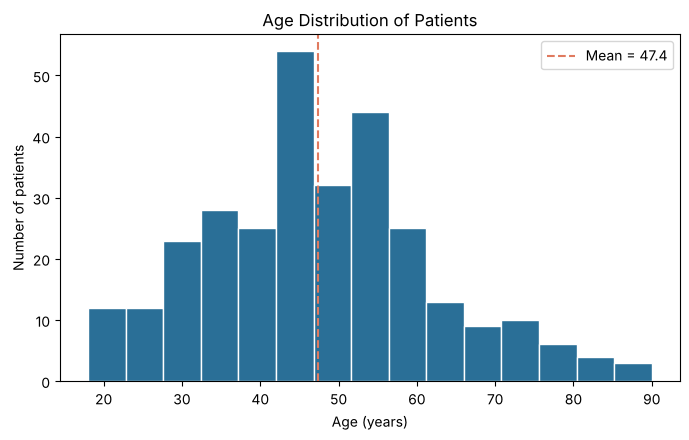

In [7]:
visualization.plot_age_distribution(clean);

**Interpretation:** ages are roughly bell-shaped, centred in the mid-40s, with a long tail towards older patients. Patients under 30 and over 75 are the smallest groups, so prevalence estimates for those groups are less stable.

### 4.2 Condition prevalence by age group

age_group
<30       3.0
30-44    12.4
45-59    27.8
60-74    59.5
75+      61.5
Name: hypertension, dtype: float64


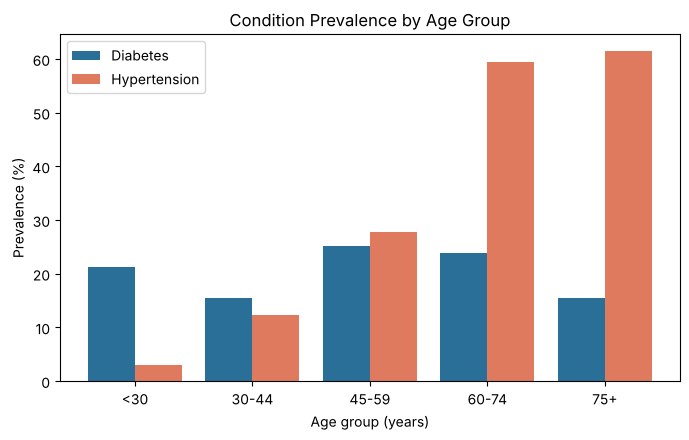

In [8]:
visualization.plot_prevalence_by_age_group(clean);
print(analysis.prevalence_by_group(clean, 'age_group', 'hypertension'))

**Interpretation:** hypertension prevalence climbs steeply with age (about 60% from age 60), while diabetes prevalence is flatter and noisier. With only 300 simulated patients, small groups can fluctuate.

### 4.3 Blood glucose by diabetes status

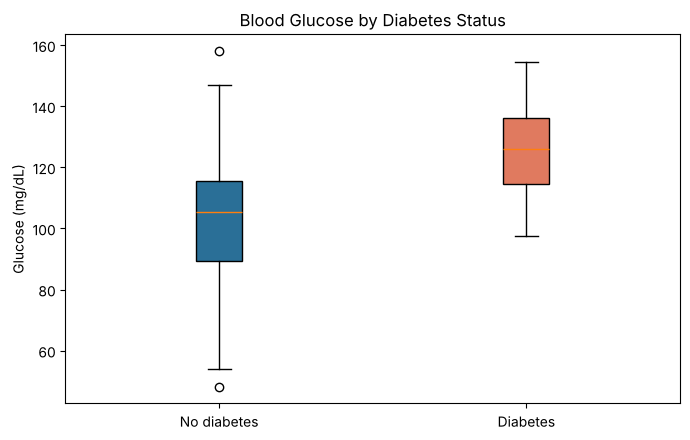

In [9]:
visualization.plot_glucose_by_diabetes(clean);

**Interpretation:** patients with diabetes have clearly higher glucose levels (higher median, little overlap with the lower half of the non-diabetic group), as expected.

### 4.4 BMI versus systolic blood pressure

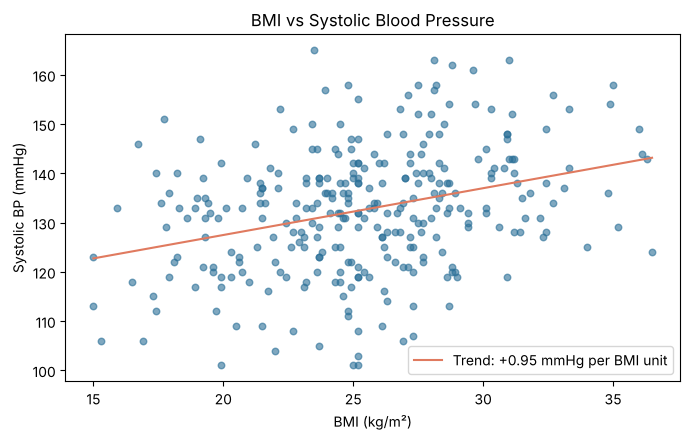

In [10]:
visualization.plot_bmi_vs_bp(clean);

**Interpretation:** systolic BP rises with BMI (roughly +1 mmHg per BMI unit); the scatter is wide, so BMI explains only part of the variation.

### 4.5 Correlation heatmap

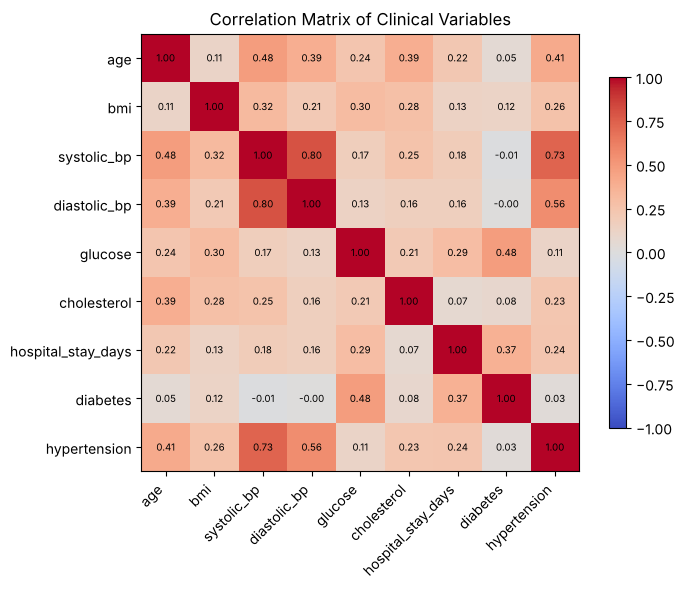

In [11]:
visualization.plot_correlation_heatmap(clean);

**Interpretation:** the strongest relationships are systolic–diastolic BP and BP–hypertension (partly by construction, since hypertension is defined by systolic BP). Age is moderately correlated with BP and cholesterol; glucose is the main correlate of diabetes. Correlation does not imply causation.

## 5. Group comparison

In [12]:
print(analysis.group_comparison(clean, 'smoker', 'systolic_bp'))
print()
print(analysis.group_comparison(clean, 'bmi_category', 'glucose'))

        count    mean  median
smoker                       
No        218  131.27   132.0
Yes        82  136.15   136.5

              count    mean  median
bmi_category                       
Underweight      19   99.56  102.70
Normal          118  103.74  105.45
Overweight      119  108.38  110.40
Obese            44  118.80  118.30


## 6. Key findings

In [13]:
for finding in analysis.key_findings(clean):
    print('•', finding)

• 300 patients analysed; mean age 47.4 years.
• Diabetes prevalence: 21.0%; hypertension prevalence: 26.0%.
• Diabetes prevalence is highest in the 45-59 age group (25.2%).
• BMI and systolic BP are positively correlated (r = 0.32).
• Mean systolic BP: smokers 136.1 vs non-smokers 131.3 mmHg.


## 7. Conclusion and limitations
- The pipeline turns a messy raw file into a clean dataset and a repeatable set of statistics and charts.
- The data are **simulated**, so findings illustrate the method and must not be used for clinical conclusions.
- Median imputation is simple; it can understate variability. Future work could use model-based imputation and statistical tests (e.g. chi-square, t-tests).